# Tema 23 · Atención y transformers

El mecanismo que permite a cada parte de un texto o una imagen mirar a las demás.

Este cuaderno es el tema 23 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/23-atencion-y-transformers/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

# Teoría

## La pregunta

Lee estas dos frases:

- «Ana sacó plata del **banco**».
- «Ana se sentó en el **banco** de la plaza».

La palabra es la misma, pero tú sabes al instante que en la primera es un lugar donde se guarda dinero y en la segunda, un asiento. ¿Cómo lo sabes? Porque no lees «banco» sola: la miras **junto con las demás palabras**. «Plata» empuja hacia un significado; «se sentó» y «plaza», hacia el otro.

En el tema 22 cada palabra se convirtió en un vector, su *embedding*. Pero ese vector es siempre el mismo: «banco» tiene un único vector en las dos frases. Hace falta un mecanismo que deje a cada palabra **mirar a las otras** y mezclar en su vector lo que le sirve de ellas. Ese mecanismo se llama **atención**, y es la pieza central de los **transformers**, la arquitectura detrás de los traductores automáticos, de los modelos de lenguaje como los chatbots y, como verás al final, de muchos modelos que miran imágenes.

En este tema vas a:

- calcular a mano y en código la **atención de producto punto escalada**, softmax(QKᵀ/√d)·V;
- explicar las **consultas**, **claves** y **valores** con una analogía y con matrices;
- programar en PyTorch la atención con **varias cabezas**, comprobarla contra `nn.MultiheadAttention` y armar un **bloque transformer** completo;
- explicar la **máscara causal**, la **codificación posicional** y la diferencia entre codificador y decodificador;
- entrenar un transformer pequeño que aprende a **invertir** una secuencia de dígitos y mirar a dónde atiende;
- partir una imagen en **parches** y tratarlos como palabras, como hace un *Vision Transformer*.

Necesitas el softmax del tema 8, el MLP del tema 16, lo de los temas 18 y 19 (tensores, `nn.Module`, el bucle de entrenamiento, Adam y la normalización por lotes), la máscara de relleno del tema 21 y lo del tema 22 (embeddings y `nn.Embedding`). No vamos a usar ningún modelo ya entrenado: todo se construye desde cero.

## Actividad: ¿a quién mira cada palabra?

La frase de abajo tiene siete palabras. Cada una tiene dos vectores de juguete de dos números: una **consulta** (lo que la palabra busca) y una **clave** (lo que la palabra ofrece). En el plano, la flecha coral es la consulta de la palabra elegida y los puntos son las claves de todas. Cuanto más apunten en la misma dirección la consulta de una palabra y la clave de otra (y cuanto más largas sean), más la mira. Elige una palabra (pasa el cursor, tócala o recórrelas con el teclado): los arcos salen de ella hacia las demás, más gruesos cuanto mayor es el peso de atención, y las barras de abajo dan los porcentajes, que siempre suman 100 %.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/23-atencion-y-transformers/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Elige «banco». ¿A qué palabra mira más? Ahora elige «la» y «guardó»: ¿a quién miran?
2. Arrastra la consulta de «banco» (la flecha coral) hasta que mire sobre todo a «Ana». Después devuélvela con «Volver al inicio».
3. Baja la temperatura al mínimo y súbela al máximo. ¿Qué pasa con los arcos? ¿Hay alguna temperatura en la que todas las palabras reciban lo mismo?
4. Elige «el» y activa el interruptor «Causal». ¿A dónde se fue el arco más grueso? ¿Qué palabra puede mirar la primera palabra, «Ana», con la máscara puesta?
5. Arrastra la clave de «plata» lejos del centro, en la misma dirección. ¿Por qué ahora casi todas las palabras la miran a ella?

Los vectores de la actividad los elegimos a mano, en dos dimensiones, para que se puedan dibujar. En un transformer de verdad tienen decenas o cientos de números y **no los elige nadie**: salen de multiplicar el embedding de cada palabra por matrices que se aprenden con el descenso de gradiente.

## Leer palabra por palabra no alcanza

Antes de los transformers, los textos se procesaban sobre todo con **redes recurrentes** (RNN): una red que lee una palabra, actualiza un vector de «memoria» y pasa a la siguiente. No las vamos a programar, pero conviene saber por qué se dejaron de lado:

- **Se olvidan.** Toda la frase tiene que pasar por un único vector de memoria, palabra tras palabra. Lo que se leyó cincuenta palabras atrás llega muy desgastado.
- **Son lentas de entrenar.** Para procesar la palabra 100 hay que haber procesado antes la 99, y antes la 98. No se puede repartir el trabajo entre muchos núcleos a la vez.

La atención resuelve las dos cosas: cada palabra mira **directamente** a cualquier otra, esté a una o a mil posiciones, y todas las palabras hacen sus cuentas **al mismo tiempo**, con productos de matrices.

## La atención es una búsqueda suave

Piensa en un diccionario de Python (tema 2). Le das una **clave** y te devuelve el **valor** guardado con esa clave exacta. Si la clave no está, error. La atención es una versión suave de lo mismo:

- Cada palabra hace una **consulta** (*query*, *q*): un vector que describe lo que busca.
- Cada palabra ofrece una **clave** (*key*, *k*): un vector que describe lo que tiene.
- Cada palabra guarda un **valor** (*value*, *v*): el contenido que entrega si la miran.

En lugar de buscar la clave exacta, la consulta se compara con **todas** las claves con un producto punto (el «parecido» entre vectores del tema 3). Esos parecidos se convierten en pesos que suman 1 con un softmax, y la respuesta es el **promedio de los valores**, ponderado por esos pesos. Si una clave se parece muchísimo a la consulta, casi todo el peso va a ella y se comporta como el diccionario; si varias se parecen, la respuesta mezcla sus valores.

Con todas las consultas en las filas de una matriz *Q*, las claves en *K* y los valores en *V*, la cuenta completa es una sola fórmula:

$$\text{Atención} ( Q , K , V ) = \text{softmax} ( \frac{Q {K}^{T}}{\sqrt{d}} ) V$$

- *QK*ᵀ es la tabla de todos los productos punto: en la fila *i*, columna *j*, cuánto le interesa la palabra *j* a la palabra *i*.
- *d* es el largo de cada consulta y cada clave; dividir por √*d* mantiene los puntajes en una escala razonable (lo vemos enseguida).
- El softmax se aplica **a cada fila**: los pesos de cada palabra suman 1.
- Multiplicar por *V* hace los promedios ponderados.

### A mano, con tres palabras

Tres palabras, cada una con una consulta, una clave y un valor de dos números (*d* = 2), elegidos a mano para poder seguir las cuentas.

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Una fila por palabra: «Ana», «sacó», «plata»
Q = torch.tensor([[0.0, 1.0],
                  [1.0, 1.0],
                  [2.0, 0.0]])
K = torch.tensor([[0.0, 2.0],
                  [1.0, 0.0],
                  [2.0, 1.0]])
V = torch.tensor([[1.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 1.0]])

puntajes = Q @ K.T / math.sqrt(2)       # (3, 3): cada palabra con cada otra
pesos = torch.softmax(puntajes, dim=-1)  # cada fila suma 1
salida = pesos @ V                       # promedios ponderados de los valores

print("Puntajes:\n", puntajes.round(decimals=2))
print("Pesos:\n", pesos.round(decimals=2))
print("Suma de cada fila:", pesos.sum(dim=-1))
print("Salida:\n", salida.round(decimals=2))

Puntajes:
 tensor([[1.4100, 0.0000, 0.7100],
        [1.4100, 0.7100, 2.1200],
        [0.0000, 1.4100, 2.8300]])
Pesos:
 tensor([[0.5800, 0.1400, 0.2800],
        [0.2800, 0.1400, 0.5800],
        [0.0500, 0.1900, 0.7700]])
Suma de cada fila: tensor([1.0000, 1.0000, 1.0000])
Salida:
 tensor([[0.8600, 0.4200],
        [0.8600, 0.7200],
        [0.8100, 0.9500]])


Sigue la primera fila con lápiz. La consulta de «Ana» es (0, 1). Sus productos punto con las tres claves son 0·0 + 1·2 = 2, 0·1 + 1·0 = 0 y 0·2 + 1·1 = 1. Divididos por √2 ≈ 1,41 quedan 1,41, 0 y 0,71. El softmax los convierte en 0,58, 0,14 y 0,28: «Ana» mira sobre todo a la primera palabra (a sí misma). Su salida es 0,58·(1, 0) + 0,14·(0, 1) + 0,28·(1, 1) = (0,86; 0,42). Cada palabra sale de la atención con un vector nuevo, que es una mezcla de los valores de toda la frase.

### ¿Por qué dividir por √d?

El producto punto suma *d* productos. Si los números de *q* y *k* son al azar, con desviación 1, la suma crece con *d*: su desviación estándar es √*d*. Con *d* = 512, los puntajes serían del orden de 20 o 30, y un softmax con números así de grandes pone casi todo el peso en una sola palabra. Eso es malo para entrenar: el gradiente del softmax casi se anula y la red deja de aprender.

In [ ]:
for dim in [2, 64, 512]:
    q = torch.randn(1000, dim)           # 1000 consultas al azar
    k = torch.randn(8, dim)              # 8 claves al azar
    punto = q @ k.T                      # (1000, 8)
    escalado = punto / math.sqrt(dim)
    # El peso más grande de cada fila, en promedio
    p_sin = torch.softmax(punto, dim=-1).max(dim=-1).values.mean()
    p_con = torch.softmax(escalado, dim=-1).max(dim=-1).values.mean()
    print(f"d = {dim:3d}: desviación {punto.std():5.1f} -> "
          f"{escalado.std():.2f}   peso máximo {p_sin:.2f} -> "
          f"{p_con:.2f}")

d =   2: desviación   1.5 -> 1.05   peso máximo 0.40 -> 0.32
d =  64: desviación   8.0 -> 1.00   peso máximo 0.87 -> 0.36
d = 512: desviación  23.3 -> 1.03   peso máximo 0.96 -> 0.37


Sin escalar, con *d* = 512 el softmax le da a una sola clave casi todo el peso, aunque las claves sean puro azar. Al dividir por √*d*, la desviación vuelve a ser cercana a 1 para cualquier *d* y el peso máximo queda parecido en los tres casos.

### La temperatura

Dividir los puntajes por un número antes del softmax es tan útil que tiene nombre: **temperatura** *T*.

$${p}_{j} = \frac{{e}^{{s}_{j} / T}}{\sum_{m} {e}^{{s}_{m} / T}}$$

Con *T* chica, las diferencias entre puntajes se agrandan y el softmax **enfoca** casi todo en el más grande. Con *T* grande, las diferencias se achican y el softmax **reparte**. La división por √*d* de la atención es una temperatura fija, *T* = √*d*. En el tema 24 vas a ver la temperatura otra vez, al elegir la siguiente palabra de un modelo de lenguaje.

T = 0.25: [0.98 0.02 0.   0.  ]
T = 0.5: [0.84 0.11 0.04 0.  ]
T = 1: [0.61 0.22 0.14 0.03]
T = 4: [0.34 0.27 0.23 0.16]


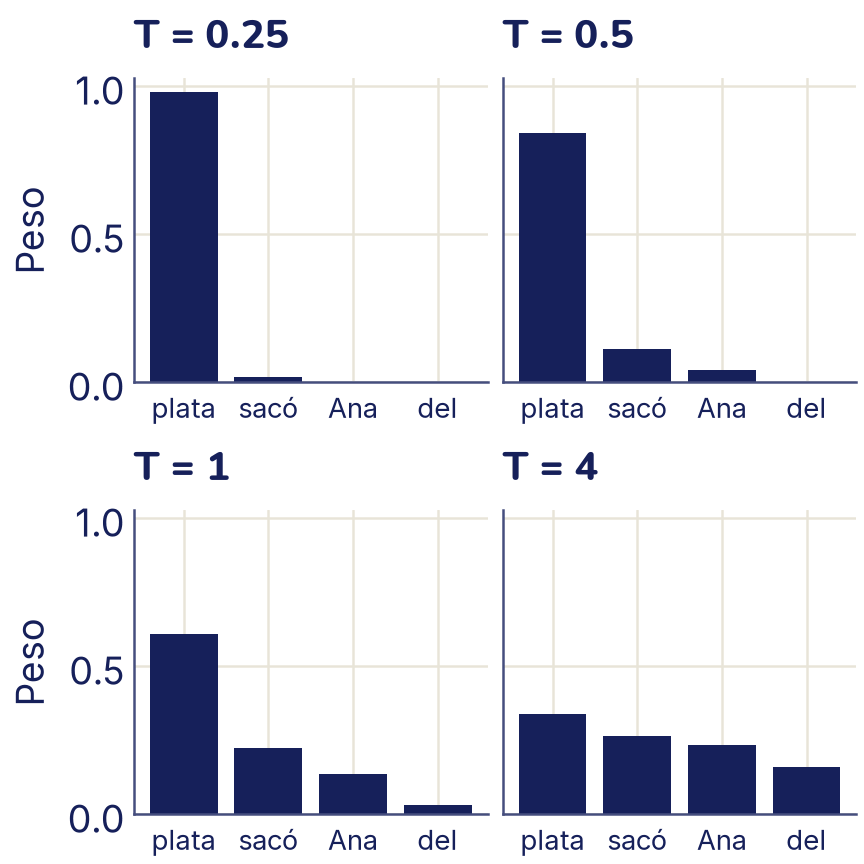

In [ ]:
palabras = ["plata", "sacó", "Ana", "del"]
s = torch.tensor([2.0, 1.0, 0.5, -1.0])   # puntajes de una fila

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8), sharey=True)
for eje, T in zip(ejes.flat, [0.25, 0.5, 1, 4]):
    p = torch.softmax(s / T, dim=0)
    print(f"T = {T}:", np.round(p.numpy(), 2))
    eje.bar(palabras, p, color="C0")
    eje.set_title(f"T = {T}")
    eje.tick_params(axis="x", labelsize=11)
for eje in ejes[:, 0]:
    eje.set_ylabel("Peso")
plt.show()

El orden de las palabras nunca cambia: «plata» siempre recibe más que «sacó». La temperatura solo decide **qué tan concentrada** está la atención. Es el deslizador de la actividad.

## La atención en PyTorch

Esta es toda la atención, en una función que sirve para cualquier forma de lote. Lleva un argumento más, la **máscara**, que explicamos en un momento: marca con `True` las casillas que no se pueden mirar.

In [ ]:
def atencion(Q, K, V, mascara=None):
    """Atención de producto punto escalada.

    Q: (..., Lq, d)   K: (..., Lk, d)   V: (..., Lk, dv)
    mascara: True donde NO se puede mirar (o None).
    Devuelve la salida (..., Lq, dv) y los pesos (..., Lq, Lk).
    """
    d = Q.shape[-1]
    puntajes = Q @ K.transpose(-2, -1) / math.sqrt(d)
    if mascara is not None:
        # -inf: después del softmax, peso exactamente 0
        puntajes = puntajes.masked_fill(mascara, float("-inf"))
    pesos = torch.softmax(puntajes, dim=-1)
    return pesos @ V, pesos

salida_f, pesos_f = atencion(Q, K, V)
print("Igual que a mano:", torch.allclose(salida_f, salida))

# Un lote de 4 frases, 2 «cabezas», 10 palabras, vectores de 8
q = torch.randn(4, 2, 10, 8)
salida_lote, pesos_lote = atencion(q, q, q)
print("Salida:", salida_lote.shape, "  Pesos:", pesos_lote.shape)

Igual que a mano: True
Salida: torch.Size([4, 2, 10, 8])   Pesos: torch.Size([4, 2, 10, 10])


¿Por qué −∞? El softmax calcula e<sup>puntaje</sup> para cada casilla y después reparte el 100 % en proporción. Como e<sup>−∞</sup> = 0, una casilla con puntaje −∞ no recibe nada, y las demás se reparten todo el peso. Por eso, poner −∞ antes del softmax es la forma de prohibir mirar una casilla.

`K.transpose(-2, -1)` traspone solo las dos últimas dimensiones, así que la misma línea funciona para una frase o para un lote de frases con varias cabezas: las dimensiones de adelante se recorren solas (es el *broadcasting* del tema 3).

## Autoatención con varias cabezas

¿De dónde salen *Q*, *K* y *V*? En la **autoatención** salen de la misma frase. Cada palabra llega con su vector *x* (su embedding, de largo *d*<sub>modelo</sub>), y tres capas lineales lo convierten en su consulta, su clave y su valor:

$$Q = X {W}_{Q} \qquad K = X {W}_{K} \qquad V = X {W}_{V}$$

Las matrices *W*<sub>Q</sub>, *W*<sub>K</sub> y *W*<sub>V</sub> se aprenden. Así una misma palabra puede **buscar** una cosa (su consulta) y **ofrecer** otra (su clave): «banco» puede buscar palabras de dinero o de lugar, mientras ofrece «soy un sustantivo».

Una sola atención solo puede mirar con un criterio a la vez. Por eso se usan **varias cabezas**. Primero se calculan *Q*, *K* y *V* completos de cada palabra, con las matrices de arriba; después cada uno se corta en, por ejemplo, 4 pedazos. La cabeza 1 usa el primer pedazo de *Q*, de *K* y de *V*; la cabeza 2, el segundo; y así. Cada cabeza hace su propia atención con sus pedazos, así que tiene sus propias consultas y claves. Una cabeza puede aprender a mirar el sujeto del verbo; otra, la palabra anterior; otra, el sustantivo al que se refiere un artículo. Al final los pedazos se vuelven a pegar y una última capa lineal los mezcla. Como cada cabeza trabaja con vectores más cortos, el costo total es parecido al de una sola cabeza grande.

In [ ]:
class AtencionMulticabeza(nn.Module):
    def __init__(self, d_modelo, cabezas):
        super().__init__()
        assert d_modelo % cabezas == 0, "d_modelo debe dividirse"
        self.cabezas = cabezas
        # Una sola capa calcula Q, K y V juntos: 3 · d_modelo salidas
        self.qkv = nn.Linear(d_modelo, 3 * d_modelo)
        self.salida = nn.Linear(d_modelo, d_modelo)

    def forward(self, x, mascara=None):
        B, L, D = x.shape                 # lote, largo, d_modelo
        # Primero Q, K y V completos: chunk parte las 3 · D salidas
        # en 3 pedazos iguales, cada uno de forma (B, L, D)
        q, k, v = self.qkv(x).chunk(3, dim=-1)

        # Una función definida dentro de otra: solo se usa aquí
        def separar(t):
            # Después, cada uno se corta en pedazos, uno por cabeza.
            # Con D = 16 y 4 cabezas: (B, L, 16) -> (B, L, 4, 4)
            t = t.view(B, L, self.cabezas, D // self.cabezas)
            # Cada cabeza al frente: (B, L, 4, 4) -> (B, 4, L, 4)
            return t.transpose(1, 2)

        o, self.pesos = atencion(separar(q), separar(k), separar(v),
                                 mascara)
        # Pegar de nuevo las cabezas: (B, L, D)
        o = o.transpose(1, 2).reshape(B, L, D)
        return self.salida(o)


torch.manual_seed(0)
capa = AtencionMulticabeza(d_modelo=16, cabezas=4)
x = torch.randn(2, 5, 16)                 # 2 frases de 5 palabras
print("Entrada:", x.shape, "  Salida:", capa(x).shape)
print("Pesos guardados:", capa.pesos.shape)

Entrada: torch.Size([2, 5, 16])   Salida: torch.Size([2, 5, 16])
Pesos guardados: torch.Size([2, 4, 5, 5])


La salida tiene la **misma forma** que la entrada: una fila por palabra, del mismo largo. Eso permite apilar muchas capas de atención, una encima de otra. Guardamos los pesos en `self.pesos` para poder dibujarlos después.

### La misma cuenta que PyTorch

PyTorch trae su propia versión, `nn.MultiheadAttention`. Guarda las tres matrices *W*<sub>Q</sub>, *W*<sub>K</sub>, *W*<sub>V</sub> pegadas en `in_proj_weight`, en ese orden, como nuestra `qkv`. Si le copiamos nuestros pesos, tiene que dar exactamente lo mismo:

In [ ]:
oficial = nn.MultiheadAttention(16, 4, batch_first=True)
with torch.no_grad():
    oficial.in_proj_weight.copy_(capa.qkv.weight)
    oficial.in_proj_bias.copy_(capa.qkv.bias)
    oficial.out_proj.weight.copy_(capa.salida.weight)
    oficial.out_proj.bias.copy_(capa.salida.bias)

nuestra = capa(x)
# Autoatención: la misma x hace de consultas, claves y valores
suya, pesos_suyos = oficial(x, x, x, average_attn_weights=False)
print("Salidas iguales:", torch.allclose(nuestra, suya, atol=1e-6))
print("Pesos iguales:  ",
      torch.allclose(capa.pesos, pesos_suyos, atol=1e-6))

Salidas iguales: True
Pesos iguales:   True


Nuestras veinte líneas hacen lo mismo que la capa de PyTorch. Desde ahora puedes usar cualquiera de las dos sabiendo qué pasa por dentro. (`atol=1e-6` acepta diferencias de redondeo en el sexto decimal: las dos versiones suman en distinto orden.)

## La máscara causal: no mirar el futuro

Un modelo que **escribe** texto, palabra por palabra, no puede mirar las palabras que todavía no escribió. Al entrenarlo, sin embargo, le damos la frase entera de una vez. Para que no haga trampa se usa una **máscara causal**: la palabra *i* solo puede mirar las palabras 0 a *i* (contando desde 0, como Python). En la tabla de puntajes, todo lo que está **arriba de la diagonal** se reemplaza por −∞ antes del softmax, y su peso queda en 0 exacto.

In [ ]:
frase = ["Ana", "sacó", "plata", "del", "banco"]
L = len(frase)
# True arriba de la diagonal: las palabras del futuro
causal = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)
print(causal.int())

torch.manual_seed(1)
q_frase = torch.randn(L, 8)
k_frase = torch.randn(L, 8)
_, pesos_causal = atencion(q_frase, k_frase, k_frase, causal)
print(pesos_causal.round(decimals=2))

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5300, 0.4700, 0.0000, 0.0000, 0.0000],
        [0.1600, 0.6700, 0.1700, 0.0000, 0.0000],
        [0.0400, 0.1400, 0.1000, 0.7200, 0.0000],
        [0.1300, 0.1900, 0.1000, 0.0500, 0.5300]])


La primera palabra solo se puede mirar a sí misma, así que su peso es 1. La última puede mirar a todas. Cada fila sigue sumando 1, porque las casillas tapadas se quedaron afuera del softmax, no se borraron después.

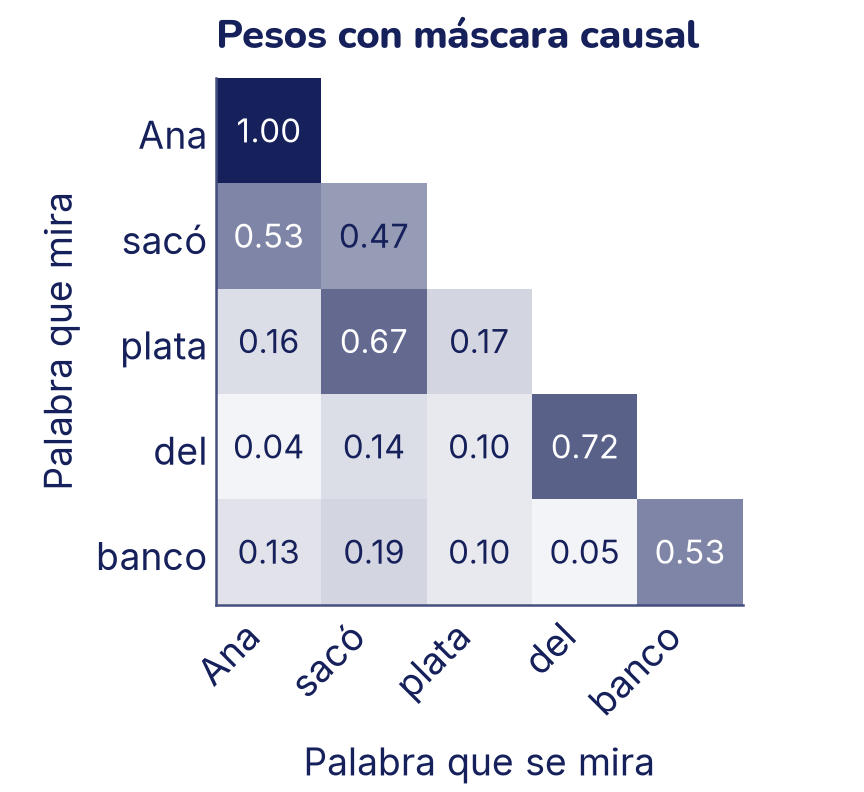

In [ ]:
# Blanco para el 0 y tinta para el 1
blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
# Las casillas del futuro quedan en blanco, sin número
tabla = np.ma.masked_where(causal.numpy(), pesos_causal.numpy())

# Una figura más alta: casillas más grandes y números legibles
fig, eje = plt.subplots(figsize=(4.8, 4.4))
eje.imshow(tabla, cmap=blanco_tinta, vmin=0, vmax=1)
for i in range(L):
    for j in range(i + 1):
        p = pesos_causal[i, j].item()
        eje.text(j, i, f"{p:.2f}", ha="center", va="center",
                 fontsize=13, color="white" if p > 0.5 else "C0")
eje.set_xticks(range(L), frase, rotation=45, ha="right")
eje.set_yticks(range(L), frase)
eje.grid(False)                         # sin rejilla sobre la tabla
eje.set_xlabel("Palabra que se mira")
eje.set_ylabel("Palabra que mira")
eje.set_title("Pesos con máscara causal")
plt.show()

Hay otra máscara que ya conoces del tema 21: la de **padding**. Cuando un lote junta frases de distinto largo y las de menos palabras se rellenan con un token de relleno, nadie debe mirar esos rellenos: se tapan sus columnas con −∞, igual que acá.

## ¿Dónde está cada palabra?

La atención tiene una propiedad sorprendente: **no sabe en qué orden vienen las palabras**. Cada palabra compara su consulta con todas las claves, pero en ninguna parte aparece la posición. Si inviertes el orden de la frase, cada palabra recibe exactamente el mismo resultado que antes, solo que en otro lugar:

In [ ]:
torch.manual_seed(0)
x = torch.randn(1, 5, 16)
al_reves = torch.tensor([4, 3, 2, 1, 0])
y = capa(x)
y_de_la_frase_al_reves = capa(x[:, al_reves])
print("Mismo resultado, en otro orden:",
      torch.allclose(y_de_la_frase_al_reves, y[:, al_reves], atol=1e-6))

Mismo resultado, en otro orden: True


Para la atención sola, «el perro persigue al gato» y «el gato persigue al perro» son la misma bolsa de palabras. La solución es **sumarle al embedding de cada palabra un vector que diga su posición**. Hay dos formas:

- **Aprendida:** una tabla `nn.Embedding(largo_máximo, d_modelo)` con un vector por posición, que se entrena como los embeddings de palabras del tema 22. Es lo que usa nuestro transformer de juguete y los ViT.
- **Sinusoidal:** el artículo original de los transformers usó ondas de seno y coseno de distintas frecuencias, sin nada que aprender. Es opcional: nuestro juguete usa la forma aprendida, pero vale la pena ver la idea.

Piensa en un reloj con muchas agujas que giran a distintas velocidades. Una aguja rápida cambia mucho de una posición a la siguiente: sirve para distinguir posiciones vecinas. Una aguja lenta casi no se mueve de una posición a la siguiente, pero después de cientos de posiciones está en otro lugar: sirve para distinguir el principio del final de un texto largo. Juntas, las agujas dan una combinación distinta en cada posición. El seno y el coseno (los de trigonometría, que suben y bajan entre −1 y 1 una y otra vez) hacen de agujas: cada par de columnas del vector es una aguja, y el número 10000<sup>2*i*/*d*</sup> decide qué tan despacio gira la aguja *i*. Con *i* = 0 el divisor es 1 y la aguja gira rápido; con *i* grande, el divisor se acerca a 10 000 y gira muy despacio:

$${\mathrm{PE}}_{( \mathrm{pos} , 2 i )} = \mathrm{sen} ( \frac{\mathrm{pos}}{{10000}^{2 i / d}} ) \qquad {\mathrm{PE}}_{( \mathrm{pos} , 2 i + 1 )} = \mathrm{cos} ( \frac{\mathrm{pos}}{{10000}^{2 i / d}} )$$

Las primeras columnas son las agujas rápidas y las últimas, las lentas. Ninguna posición tiene el mismo vector que otra.

torch.Size([50, 32])
tensor([[ 0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8400,  0.5400,  0.5300,  0.8500],
        [ 0.9100, -0.4200,  0.9000,  0.4300]])


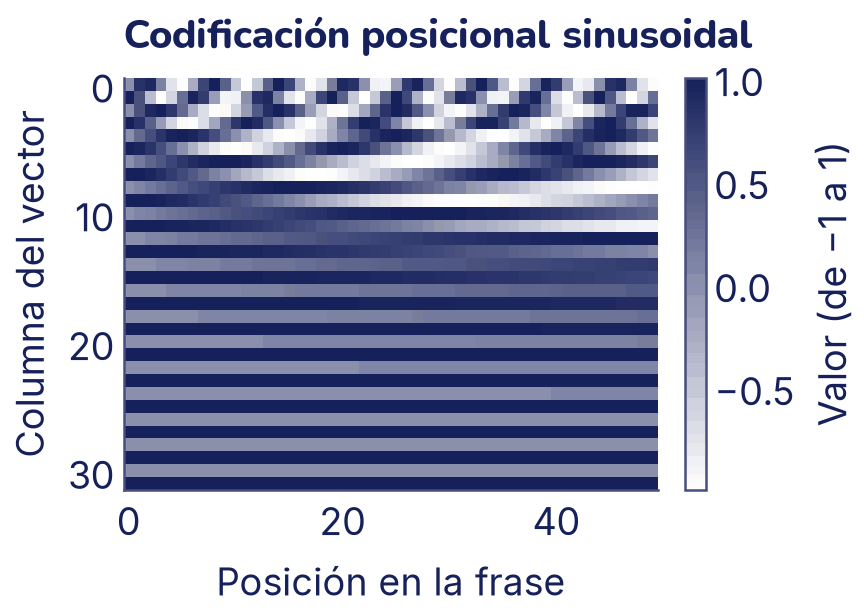

In [ ]:
def posicion_sinusoidal(largo, d_modelo):
    pos = torch.arange(largo).unsqueeze(1)          # (largo, 1)
    i = torch.arange(0, d_modelo, 2)                # 0, 2, 4, ...
    frecuencia = 1 / 10000 ** (i / d_modelo)        # (d_modelo / 2,)
    pe = torch.zeros(largo, d_modelo)
    pe[:, 0::2] = torch.sin(pos * frecuencia)       # columnas pares
    pe[:, 1::2] = torch.cos(pos * frecuencia)       # columnas impares
    return pe

pe = posicion_sinusoidal(50, 32)
print(pe.shape)
print(pe[:3, :4].round(decimals=2))

plt.imshow(pe.T, cmap=blanco_tinta, aspect="auto")
plt.grid(False)
plt.colorbar(label="Valor (de −1 a 1)")
plt.xlabel("Posición en la frase")
plt.ylabel("Columna del vector")
plt.title("Codificación posicional sinusoidal")
plt.show()

Cada columna de la figura es el vector de una posición: una especie de código de barras único. La posición 0 es (0, 1, 0, 1, …), porque sen 0 = 0 y cos 0 = 1.

## El bloque transformer

La atención mezcla información **entre** palabras. Un transformer la combina con otras tres piezas, y las cuatro juntas forman un **bloque** que se repite muchas veces, uno encima de otro:

1. **Atención con varias cabezas**: cada palabra recoge información de las demás.
2. **Un MLP** (tema 16) que se aplica a cada palabra **por separado**: procesa lo que la palabra acaba de recoger. Suele tener una capa oculta 4 veces más ancha que *d*<sub>modelo</sub>.
3. **Conexiones residuales**: la salida de cada pieza se **suma** a su entrada, *x* + atención(*x*), en vez de reemplazarla. Cada capa solo tiene que aprender una corrección, y el gradiente tiene un camino directo hacia las primeras capas. Sin ellas, apilar decenas de bloques no entrena.
4. **LayerNorm**: antes de cada pieza, el vector de **cada palabra** se normaliza para que tenga media 0 y desviación 1 (y después se escala con dos vectores aprendidos). Se parece a la normalización por lotes del tema 19, pero no promedia a través del lote sino a lo largo del vector de cada palabra: funciona igual con lotes de una sola frase y con frases de cualquier largo.

In [ ]:
ln = nn.LayerNorm(4)
palabra = torch.tensor([[1.0, 2.0, 3.0, 4.0]])
print(ln(palabra).detach().round(decimals=2))

tensor([[-1.3400, -0.4500,  0.4500,  1.3400]])


El dibujo del bloque, de abajo hacia arriba (el código solo dibuja el diagrama: no hace falta entenderlo línea por línea):

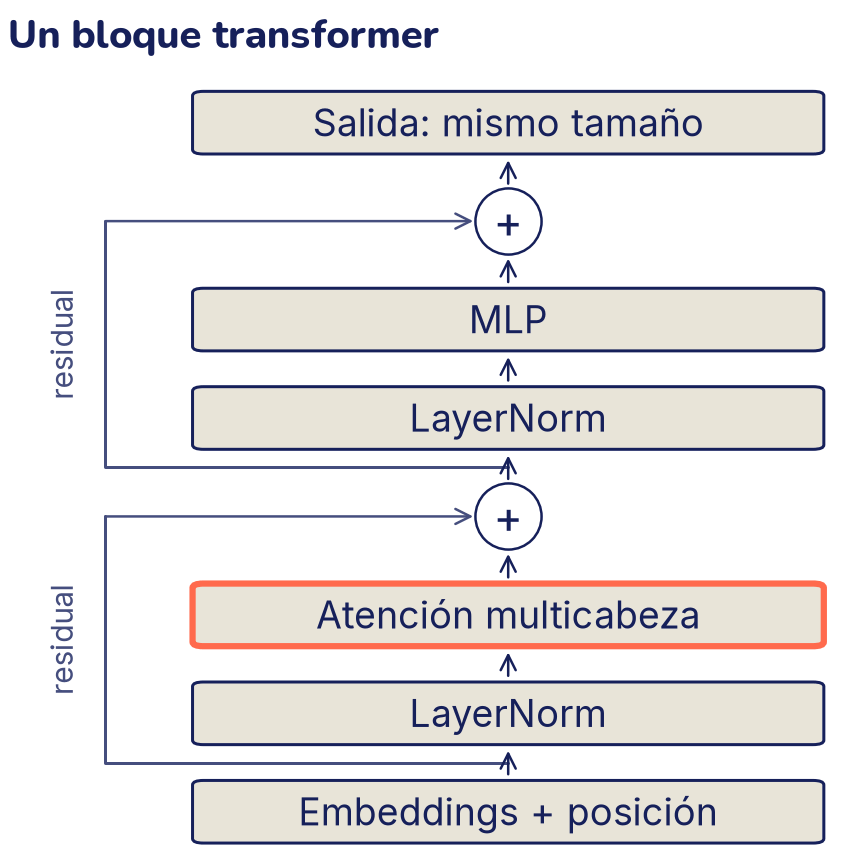

In [ ]:
# Solo para dibujar: cajas y flechas del diagrama del bloque
from matplotlib.patches import FancyBboxPatch

fig, eje = plt.subplots(figsize=(4.8, 4.8))
cajas = [  # (texto, centro y), de abajo hacia arriba
    ("Embeddings + posición", 0.5),
    ("LayerNorm", 1.6),
    ("Atención multicabeza", 2.7),
    ("LayerNorm", 4.9),
    ("MLP", 6.0),
    ("Salida: mismo tamaño", 8.2),
]
sumas = [3.8, 7.1]                      # los dos signos +
for texto, y in cajas:
    clave = texto.startswith("Atención")
    eje.add_patch(FancyBboxPatch(
        (0.8, y - 0.3), 2.8, 0.6, boxstyle="round,pad=0.05",
        facecolor="C3", edgecolor="C1" if clave else "C0",
        linewidth=2.5 if clave else 1.2))
    eje.text(2.2, y, texto, ha="center", va="center")
for y in sumas:
    eje.scatter([2.2], [y], s=700, facecolor="white", edgecolor="C0",
                zorder=3)
    eje.text(2.2, y, "+", ha="center", va="center", fontsize=18,
             zorder=4)
# Flechas del camino principal, de centro a centro
centros = sorted([y for _, y in cajas] + sumas)
for y0, y1 in zip(centros[:-1], centros[1:]):
    eje.annotate("", (2.2, y1), (2.2, y0),
                 arrowprops=dict(arrowstyle="->", color="C0",
                                 shrinkA=15, shrinkB=15))
# Los atajos residuales: la entrada de cada parte va directo al +
for y_desde, y_hasta in [(1.05, 3.8), (4.35, 7.1)]:
    eje.plot([2.2, 0.35, 0.35], [y_desde, y_desde, y_hasta],
             color="C2", linewidth=1.2)
    eje.annotate("", (2.2, y_hasta), (0.35, y_hasta),
                 arrowprops=dict(arrowstyle="->", color="C2",
                                 shrinkA=0, shrinkB=14))
    eje.text(0.15, (y_desde + y_hasta) / 2, "residual", rotation=90,
             color="C2", fontsize=12, ha="center", va="center")
eje.set_xlim(-0.1, 3.8)
eje.set_ylim(0, 8.7)
eje.axis("off")
eje.set_title("Un bloque transformer")
plt.show()

Y en código, con la atención que ya programamos. El orden «primero LayerNorm, después la pieza, después la suma» es el que usan casi todos los modelos actuales (se llama *pre-norm*; el artículo original normalizaba después de la suma).

In [ ]:
class BloqueTransformer(nn.Module):
    def __init__(self, d_modelo, cabezas, d_mlp):
        super().__init__()
        self.norma1 = nn.LayerNorm(d_modelo)
        self.atencion = AtencionMulticabeza(d_modelo, cabezas)
        self.norma2 = nn.LayerNorm(d_modelo)
        self.mlp = nn.Sequential(nn.Linear(d_modelo, d_mlp), nn.ReLU(),
                                 nn.Linear(d_mlp, d_modelo))

    def forward(self, x, mascara=None):
        # Las palabras se miran entre sí, y se suma (residual)
        x = x + self.atencion(self.norma1(x), mascara)
        # Cada palabra se procesa por separado, y se suma
        x = x + self.mlp(self.norma2(x))
        return x


def contar(modelo):
    return sum(p.numel() for p in modelo.parameters())

bloque = BloqueTransformer(d_modelo=64, cabezas=4, d_mlp=256)
print("Forma:", bloque(torch.randn(2, 10, 64)).shape)
print("Parámetros del bloque:", contar(bloque))
print("  atención:", contar(bloque.atencion),
      "  MLP:", contar(bloque.mlp),
      "  LayerNorm:", contar(bloque.norma1) + contar(bloque.norma2))

# El bloque equivalente que trae PyTorch
suyo = nn.TransformerEncoderLayer(64, 4, dim_feedforward=256,
                                  dropout=0.0, batch_first=True,
                                  norm_first=True)
print("Parámetros del de PyTorch:", contar(suyo))

Forma: torch.Size([2, 10, 64])
Parámetros del bloque: 49984
  atención: 16640   MLP: 33088   LayerNorm: 256
Parámetros del de PyTorch: 49984


Los 49 984 parámetros salen de cuentas que puedes hacer a mano (ejercicio 4). La atención tiene 4 matrices de 64 × 64 (*W*<sub>Q</sub>, *W*<sub>K</sub>, *W*<sub>V</sub> y la de salida) con sus sesgos; el MLP, dos matrices de 64 × 256 con los suyos, y es la parte más grande. Fíjate en que **la cantidad de parámetros no depende del largo de la frase**: el mismo bloque procesa 10 palabras o 1000.

## Codificador, decodificador y los dos juntos

Con bloques como este se arman tres familias de modelos. Cambia sobre todo la máscara:

| Familia | Máscara | Para qué sirve | Ejemplos |
|---|---|---|---|
| **Codificador** | Ninguna: cada palabra mira a todas | Entender un texto entero: clasificar, buscar, etiquetar palabras | BERT (tema 25), ViT |
| **Decodificador** | Causal: solo el pasado | Escribir texto palabra por palabra | GPT y los modelos de lenguaje (tema 24) |
| **Codificador-decodificador** | Codificador sin máscara; decodificador causal y además mira al codificador | Transformar un texto en otro: traducir, resumir | El transformer original, T5 (tema 25) |

En el codificador-decodificador aparece una variante, la **atención cruzada**: las consultas salen del texto que se está escribiendo y las claves y valores, del texto de entrada. Es la misma función `atencion`, con *Q* de un lado y *K* y *V* del otro.

### El costo cuadrático

La atención tiene un precio: la tabla de pesos tiene una casilla por **cada par** de palabras. Con *L* palabras son *L*² números, por cada cabeza y cada bloque.

In [ ]:
for L_texto in [100, 1_000, 10_000, 100_000]:
    casillas = L_texto ** 2
    # 4 bytes por número (float32)
    print(f"{L_texto:>7,} palabras: {casillas:>15,} pesos "
          f"= {casillas * 4 / 1e6:>9,.2f} MB por cabeza")

    100 palabras:          10,000 pesos =      0.04 MB por cabeza
  1,000 palabras:       1,000,000 pesos =      4.00 MB por cabeza
 10,000 palabras:     100,000,000 pesos =    400.00 MB por cabeza
100,000 palabras:  10,000,000,000 pesos = 40,000.00 MB por cabeza


Diez veces más palabras significan cien veces más cuentas y memoria. Por eso los modelos tienen un **largo máximo** de contexto, y por eso hay tanta investigación en atenciones más baratas.

## Un transformer de juguete: invertir dígitos

Ahora juntemos todo y entrenemos un transformer de verdad. La tarea: recibir 8 dígitos y devolverlos **al revés**. Para una persona es trivial; para una red es un buen examen, porque la respuesta en cada posición depende de **otra** posición. Los datos son **sintéticos**: secuencias de dígitos al azar.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

LARGO, DIGITOS = 8, 10
g = torch.Generator().manual_seed(0)
X_ent = torch.randint(0, DIGITOS, (20000, LARGO), generator=g)
X_val = torch.randint(0, DIGITOS, (2000, LARGO), generator=g)
# La respuesta: la misma secuencia, al revés
Y_ent, Y_val = X_ent.flip(dims=[1]), X_val.flip(dims=[1])
print("Entrada: ", X_ent[0].tolist())
print("Objetivo:", Y_ent[0].tolist())

Entrada:  [4, 9, 3, 0, 3, 9, 7, 3]
Objetivo: [3, 7, 9, 3, 0, 3, 9, 4]


El modelo es un **codificador**: embeddings de los dígitos (una tabla `nn.Embedding`, como en el tema 22) más embeddings de posición aprendidos, un bloque transformer y una capa lineal que, en cada posición, da 10 logits, uno por dígito.

In [ ]:
class TransformerJuguete(nn.Module):
    def __init__(self, d_modelo=32, cabezas=2, bloques=1,
                 con_posicion=True):
        super().__init__()
        self.fichas = nn.Embedding(DIGITOS, d_modelo)
        self.posicion = (nn.Embedding(LARGO, d_modelo)
                         if con_posicion else None)
        self.bloques = nn.ModuleList(
            [BloqueTransformer(d_modelo, cabezas, 4 * d_modelo)
             for _ in range(bloques)])
        self.norma = nn.LayerNorm(d_modelo)
        self.salida = nn.Linear(d_modelo, DIGITOS)

    def forward(self, x):                 # x: (B, L) con dígitos
        z = self.fichas(x)                # (B, L, d_modelo)
        if self.posicion is not None:
            z = z + self.posicion(torch.arange(x.shape[1],
                                               device=x.device))
        for bloque in self.bloques:
            z = bloque(z)
        return self.salida(self.norma(z))  # (B, L, 10)

torch.manual_seed(0)
modelo = TransformerJuguete()
print("Parámetros:", contar(modelo))

Parámetros: 13674


Para entrenar no sirve tal cual la función `entrenar` del tema 18: cuenta **una** respuesta por ejemplo, y aquí cada ejemplo tiene **ocho** (un dígito por posición). Escribimos un bucle corto con los mismos pasos de siempre. El único detalle nuevo es que `nn.CrossEntropyLoss` quiere las clases en la dimensión 1, así que los logits pasan de (B, L, 10) a (B, 10, L) con `transpose`.

In [ ]:
def exactitud(modelo, X, Y):
    """Fracción de dígitos y de secuencias enteras acertados."""
    modelo.eval()
    with torch.no_grad():
        pred = modelo(X.to(device)).argmax(dim=-1).cpu()
    acierto = pred == Y
    por_digito = acierto.float().mean().item()
    por_secuencia = acierto.all(dim=1).float().mean().item()
    return por_digito, por_secuencia


def entrenar_secuencias(modelo, X, Y, X_v, Y_v, epocas, tasa=1e-3):
    cargador = DataLoader(TensorDataset(X, Y), batch_size=64,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa)
    funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(device)
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma = 0.0
        for x, y in cargador:
            x, y = x.to(device), y.to(device)
            optimizador.zero_grad()
            logits = modelo(x)                         # (B, L, 10)
            perdida = funcion_perdida(logits.transpose(1, 2), y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
        digitos, secuencias = exactitud(modelo, X_v, Y_v)
        # Exactitud de validación: por dígito y por secuencia entera
        print(f"Época {epoca}: pérdida {suma / len(X):.3f}   "
              f"dígitos {digitos:.1%}   secuencias {secuencias:.1%}")


entrenar_secuencias(modelo, X_ent, Y_ent, X_val, Y_val, epocas=2)

Época 1: pérdida 0.599   dígitos 100.0%   secuencias 100.0%
Época 2: pérdida 0.006   dígitos 100.0%   secuencias 100.0%


Después de una sola época, unos segundos de CPU, el modelo ya invierte el 100 % de las 2000 secuencias de validación, que nunca vio. (Las exactitudes de cada época se miden con esas secuencias de validación.) Miremos **cómo** lo hace: los pesos de atención de una de sus dos cabezas para una secuencia de validación.

Entrada:    [8, 3, 3, 9, 6, 9, 4, 0]
Predicción: [0, 4, 9, 6, 9, 3, 3, 8]


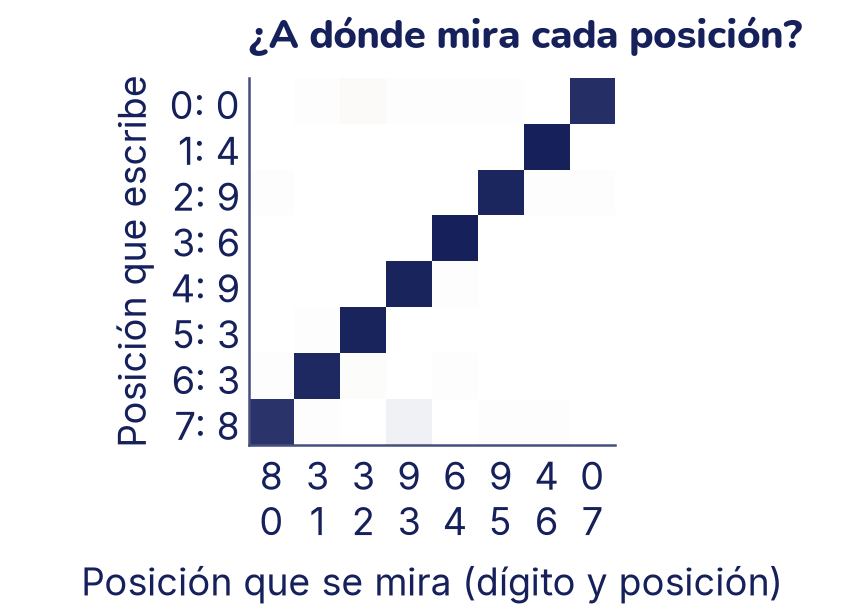

In [ ]:
ejemplo = X_val[:1].to(device)
modelo.eval()
with torch.no_grad():
    pred = modelo(ejemplo).argmax(dim=-1)
print("Entrada:   ", ejemplo[0].tolist())
print("Predicción:", pred[0].tolist())

# Los pesos de la cabeza 0 que guardó la última pasada
mapa = modelo.bloques[0].atencion.pesos[0, 0].cpu()
fig, eje = plt.subplots()
eje.imshow(mapa, cmap=blanco_tinta, vmin=0, vmax=1)
eje.grid(False)
entrada = ejemplo[0].tolist()
eje.set_xticks(range(LARGO),
               [f"{d}\n{i}" for i, d in enumerate(entrada)])
eje.set_yticks(range(LARGO),
               [f"{i}: {d}" for i, d in enumerate(pred[0].tolist())])
eje.set_xlabel("Posición que se mira (dígito y posición)")
eje.set_ylabel("Posición que escribe")
eje.set_title("¿A dónde mira cada posición?")
plt.show()

Nadie le dijo al modelo «la posición 0 tiene que mirar a la 7». Lo descubrió solo, con el descenso de gradiente: la diagonal invertida es exactamente la regla de la tarea. Cada posición pone casi todo su peso en la posición espejo y copia su dígito a través del valor.

¿Qué pasa si quitamos los embeddings de posición? Según lo que vimos antes, la atención no sabe el orden, así que no debería poder invertir nada:

In [ ]:
torch.manual_seed(0)
sin_posicion = TransformerJuguete(con_posicion=False)
entrenar_secuencias(sin_posicion, X_ent, Y_ent, X_val, Y_val,
                    epocas=2)

Época 1: pérdida 1.867   dígitos 32.1%   secuencias 0.1%
Época 2: pérdida 1.680   dígitos 31.8%   secuencias 0.0%


Sin posición, cada lugar de la salida «ve» la misma bolsa de dígitos y solo distingue el dígito que tiene en su propio lugar. Lo mejor que puede hacer es apostar por dígitos que se repiten en la secuencia: así acierta cerca de un tercio de los dígitos, pero casi ninguna secuencia entera. La posición no es un detalle: es lo que convierte una bolsa de palabras en una frase.

## Imágenes como frases: los parches

Un transformer recibe una secuencia de vectores; no le importa si vienen de palabras. El **Vision Transformer** (ViT) aprovecha eso: corta la imagen en **parches** cuadrados, aplana cada parche en un vector y trata la lista de parches como una frase. Probemos con la foto del templo que usaste en los temas 3 y 20. Para que los parches se vean grandes en la figura, nos quedamos con uno de cada cuatro píxeles y recortamos 96 × 160 píxeles: salen 6 × 10 = 60 parches de 16 × 16.

`tensor.unfold(dim, tamaño, paso)` corta una dimensión en ventanas: aplicado al alto y después al ancho, con tamaño y paso 16, da todos los parches sin un solo bucle.

Después de unfold: torch.Size([3, 6, 10, 16, 16])
Secuencia de parches: torch.Size([60, 768])
El parche 11 es el recorte correcto: True


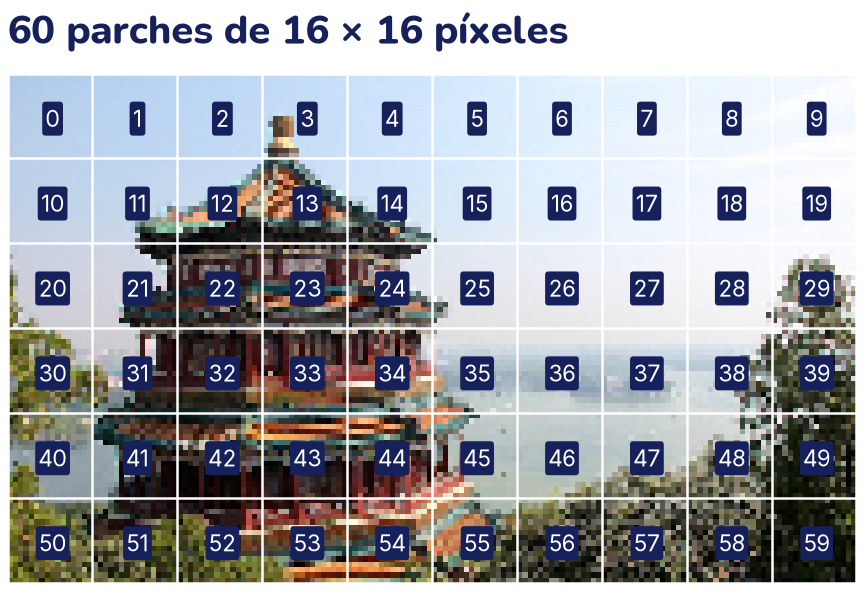

In [ ]:
from sklearn.datasets import load_sample_image

# 1 de cada 4 píxeles (para achicarla), recortada a 96 × 160,
# que son múltiplos de 16
foto = load_sample_image("china.jpg")[::4, ::4][:96, :160]
# De (alto, ancho, canal) a (canal, alto, ancho): (3, 96, 160)
imagen = torch.tensor(foto).permute(2, 0, 1) / 255
P = 16                                               # lado del parche
# Corta el alto en 6 y el ancho en 10: (3, 6, 10, 16, 16)
cortes = imagen.unfold(1, P, P).unfold(2, P, P)
print("Después de unfold:", cortes.shape)   # (C, filas, columnas, P, P)
# Ordena los ejes como (6, 10, 3, 16, 16) y aplana cada parche:
# una fila por parche, con sus 3 · 16 · 16 = 768 números -> (60, 768)
parches = cortes.permute(1, 2, 0, 3, 4).reshape(-1, 3 * P * P)
print("Secuencia de parches:", parches.shape)

# El parche 11 es fila 1, columna 1: píxeles 16 a 31 en las dos
igual = torch.equal(parches[11].view(3, P, P),
                    imagen[:, 16:32, 16:32])
print("El parche 11 es el recorte correcto:", igual)

# Solo para dibujar: la foto con el número de cada parche
filas, columnas = cortes.shape[1], cortes.shape[2]
fig, eje = plt.subplots()
eje.imshow(foto)
for k in range(filas * columnas):
    f, c = divmod(k, columnas)
    eje.text(c * P + P / 2, f * P + P / 2, str(k), ha="center",
             va="center", fontsize=9, color="white",
             bbox=dict(boxstyle="round,pad=0.15", facecolor="C0",
                       edgecolor="none"))
for f in range(filas + 1):
    eje.axhline(f * P - 0.5, color="white", linewidth=1)
for c in range(columnas + 1):
    eje.axvline(c * P - 0.5, color="white", linewidth=1)
eje.axis("off")
eje.set_title("60 parches de 16 × 16 píxeles")
plt.show()

Cada parche es ahora un vector de 768 números, como una palabra lo era en su embedding. El resto es lo que ya sabes: una capa lineal los lleva a *d*<sub>modelo</sub>, se suman embeddings de **posición** aprendidos (sin ellos, el modelo vería un rompecabezas desarmado) y se pasan por bloques transformer. Un ViT agrega además al principio un vector especial, el token **[CLS]**: no viene de ningún parche, mira a todos y, al final, su vector resume la imagen para clasificarla.

In [ ]:
torch.manual_seed(0)
d_vit = 64
proyeccion = nn.Linear(3 * P * P, d_vit)
# nn.Parameter marca un tensor como peso que se aprende, como los
# de una capa
cls = nn.Parameter(torch.zeros(1, 1, d_vit))
pos_vit = nn.Parameter(torch.zeros(1, 1 + len(parches), d_vit))

fichas_img = proyeccion(parches.unsqueeze(0))       # (1, 60, 64)
fichas_img = torch.cat([cls, fichas_img], dim=1)    # (1, 61, 64)
z = BloqueTransformer(d_vit, 4, 4 * d_vit)(fichas_img + pos_vit)
print("Tokens de la imagen:", fichas_img.shape)
print("Después del bloque: ", z.shape)
print("Resumen ([CLS]):    ", z[:, 0].shape)

Tokens de la imagen: torch.Size([1, 61, 64])
Después del bloque:  torch.Size([1, 61, 64])
Resumen ([CLS]):     torch.Size([1, 64])


Es exactamente el mismo bloque que usamos para los dígitos. Un ViT real usa fotos de 224 × 224 (196 parches), una docena de bloques y millones de imágenes para entrenarse; en el tema 26 vas a usar uno ya entrenado.

## Lo que aprendiste y lo que sigue

- La **atención** es una búsqueda suave: cada palabra compara su **consulta** con las **claves** de todas, convierte los parecidos en pesos con un softmax y se lleva el promedio ponderado de los **valores**: softmax(*QK*ᵀ/√*d*)·*V*.
- Dividir por √*d* evita que el softmax se sature cuando los vectores son largos. La **temperatura** decide si la atención se concentra o se reparte.
- En la **autoatención**, *Q*, *K* y *V* salen de la misma frase con tres capas lineales aprendidas. Con **varias cabezas**, cada una puede mirar con un criterio distinto. Nuestra versión da lo mismo que `nn.MultiheadAttention`.
- La **máscara causal** tapa el futuro con −∞ antes del softmax; la de **padding** tapa los rellenos.
- La atención no sabe el orden: hay que sumar una **codificación posicional**, aprendida o sinusoidal. Sin ella, el transformer de juguete no puede invertir los dígitos.
- Un **bloque transformer** es atención y MLP, cada uno con **LayerNorm** antes y una suma **residual** después. Los codificadores, los decodificadores y los codificadores-decodificadores se arman con estos bloques.
- La atención cuesta *L*² por cabeza: por eso los modelos tienen un largo máximo de contexto.
- Un **ViT** corta la imagen en parches, los trata como palabras y agrega un token **[CLS]** para resumir.

En el tema 24 vas a usar un decodificador con máscara causal para **generar** texto, desde un modelo que predice la siguiente letra hasta un LLM pequeño. En el 25, a reutilizar codificadores ya entrenados como BERT.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las funciones y clases de la teoría: `atencion`, `AtencionMulticabeza`, `BloqueTransformer`, `contar`, `TransformerJuguete`, `exactitud`, `entrenar_secuencias` y `blanco_tinta`, además de `LARGO` y `DIGITOS`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. Atención a mano

Tres palabras con vectores de dimensión *d* = 2:

- consultas: *q*<sub>1</sub> = (1, 1), *q*<sub>2</sub> = (0, 1), *q*<sub>3</sub> = (1, 0);
- claves: *k*<sub>1</sub> = (1, 1), *k*<sub>2</sub> = (1, −1), *k*<sub>3</sub> = (0, 0);
- valores: *v*<sub>1</sub> = (1, 0), *v*<sub>2</sub> = (0, 1), *v*<sub>3</sub> = (0, 0).

Calcula a mano (con calculadora para las exponenciales) los puntajes, los pesos y la salida de la **primera** palabra. Después calcula las tres filas con la función `atencion` y comprueba.

<details>
<summary>Respuesta</summary>

Los productos punto de *q*<sub>1</sub> con las claves son 1 + 1 = 2, 1 − 1 = 0 y 0. Divididos por √2 ≈ 1,414: 1,41, 0 y 0. Las exponenciales son *e*<sup>1,41</sup> ≈ 4,11, 1 y 1, que suman 6,11. Los pesos son 4,11/6,11 ≈ **0,67**, 1/6,11 ≈ **0,16** y **0,16**. La salida es 0,67·(1, 0) + 0,16·(0, 1) + 0,16·(0, 0) = **(0,67; 0,16)**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
Q1 = torch.tensor([[1.0, 1.0], [0.0, 1.0], [1.0, 0.0]])
K1 = torch.tensor([[1.0, 1.0], [1.0, -1.0], [0.0, 0.0]])
V1 = torch.tensor([[1.0, 0.0], [0.0, 1.0], [0.0, 0.0]])
salida1, pesos1 = atencion(Q1, K1, V1)
print("Pesos:\n", pesos1.round(decimals=2))
print("Salida:\n", salida1.round(decimals=2))

<details>
<summary>Respuesta (sigue)</summary>

La primera fila coincide con la cuenta a mano. La segunda palabra mira sobre todo a la 1 y muy poco a la 2, porque su consulta (0, 1) apunta al revés que la segunda coordenada de *k*<sub>2</sub>. La tercera reparte por igual entre la 1 y la 2 (0,40 cada una): su consulta (1, 0) se parece lo mismo a las dos claves.

</details>

### 2. Consultas, claves y valores en la vida diaria

Buscas un video en una plataforma escribiendo «cómo hacer api morado». Di qué hace de **consulta**, qué de **claves** y qué de **valores**. ¿En qué se diferencia esa búsqueda de la atención?

<details>
<summary>Respuesta</summary>

- **Consulta**: lo que escribiste.
- **Claves**: los títulos y descripciones de los videos, que se comparan con tu consulta.
- **Valores**: los videos mismos, lo que te llevas.

La plataforma te muestra una **lista** ordenada y tú eliges uno. La atención no elige: devuelve una **mezcla** de todos los valores, con más peso para los que más se parecen. Además, en la autoatención cada palabra es a la vez buscador (su consulta) y video (su clave y su valor).

</details>

### 3. Puntajes multiplicados

Toma los puntajes `s = torch.tensor([2.0, 1.0, 0.5, -1.0])` de la teoría. Sin calcular, predice qué pasa con los pesos si multiplicas todos los puntajes por 10, y si los multiplicas por 0. ¿Qué temperatura equivale a cada caso? Después compruébalo.

<details>
<summary>Respuesta</summary>

Multiplicar por 10 es lo mismo que una temperatura *T* = 0,1: casi todo el peso va al puntaje más grande. Multiplicar por 0 es como una temperatura infinita: todos los puntajes quedan en 0 y el softmax reparte por igual, 1/4 para cada uno.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("× 10:", torch.softmax(s * 10, dim=0).round(decimals=3).tolist())
print("× 0: ", torch.softmax(s * 0, dim=0).tolist())

<details>
<summary>Respuesta (sigue)</summary>

Por eso la atención sin escalar se vuelve «dura» con vectores largos (sus puntajes son grandes, como multiplicarlos por un número grande) y por eso, si todas las claves fueran iguales, cada palabra haría un promedio simple de toda la frase.

</details>

### 4. Contar los parámetros de un bloque

Un bloque transformer tiene *d*<sub>modelo</sub> = 128, 8 cabezas y un MLP con *d*<sub>mlp</sub> = 512. Cuenta a mano sus parámetros: la atención (cuatro matrices de *d* × *d* con sus sesgos), el MLP (dos capas lineales con sus sesgos) y los dos LayerNorm (cada uno tiene un vector de escala y uno de desplazamiento, de largo *d*). ¿Cambia el total si usas 2 cabezas en lugar de 8? Compruébalo con `contar`.

<details>
<summary>Respuesta</summary>

- Atención: 4 · 128 · 128 + 4 · 128 = 65 536 + 512 = **66 048**.
- MLP: 128 · 512 + 512 + 512 · 128 + 128 = **131 712**.
- LayerNorm: 2 · (128 + 128) = **512**.
- Total: **198 272**.

El número de cabezas no cambia nada: las cabezas solo **cortan** en pedazos los mismos vectores de *Q*, *K* y *V*; no agregan matrices.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for n_cabezas in [8, 2]:
    b = BloqueTransformer(d_modelo=128, cabezas=n_cabezas, d_mlp=512)
    print(f"{n_cabezas} cabezas: {contar(b):,} parámetros")

<details>
<summary>Respuesta (sigue)</summary>

El MLP tiene el doble de parámetros que la atención. En los modelos de lenguaje grandes pasa lo mismo: la mayor parte de los parámetros está en los MLP.

</details>

### 5. Encuentra el error: una máscara mal aplicada

Un compañero escribió esta atención causal. Los pesos le salen raros. Ejecútala, mira las filas y encuentra los **dos** errores.

In [ ]:
def atencion_causal_mala(Q, K, V):
    L = Q.shape[-2]
    puntajes = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])
    pesos = torch.softmax(puntajes, dim=-1)
    # Tapar el futuro
    futuro = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=0)
    pesos = pesos.masked_fill(futuro, 0.0)
    return pesos @ V, pesos

torch.manual_seed(1)
q4 = torch.randn(4, 8)
_, malos = atencion_causal_mala(q4, q4, q4)
print(malos.round(decimals=2))
print("Suma de cada fila:", malos.sum(dim=-1).round(decimals=2))

tensor([[0.0000, 0.0000, 0.0000, 0.0000],
        [0.1200, 0.0000, 0.0000, 0.0000],
        [0.1600, 0.1400, 0.0000, 0.0000],
        [0.1100, 0.0300, 0.0100, 0.0000]])
Suma de cada fila: tensor([0.0000, 0.1200, 0.3000, 0.1500])


<details>
<summary>Respuesta</summary>

1. **La máscara se aplica después del softmax.** Al poner ceros en los pesos ya calculados, las filas dejan de sumar 1: la atención pierde peso en lugar de repartirlo entre las palabras permitidas. Hay que tapar los **puntajes** con −∞ **antes** del softmax.
2. **`diagonal=0` también tapa la diagonal.** Así cada palabra no puede mirarse a sí misma, y la primera palabra no puede mirar a nadie: su fila queda toda en cero. Con la máscara bien puesta (antes del softmax) ese error daría una fila de puros −∞ y un softmax de `nan`. Lo correcto es `diagonal=1`.

La versión correcta es la función `atencion` de la teoría con la máscara `causal`:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
causal4 = torch.triu(torch.ones(4, 4, dtype=torch.bool), diagonal=1)
_, buenos = atencion(q4, q4, q4, causal4)
print(buenos.round(decimals=2))
print("Suma de cada fila:", buenos.sum(dim=-1).round(decimals=2))

### 6. ¿Necesita posición?

Sin entrenar nada, decide para cada tarea si un transformer **sin** codificación posicional podría resolverla, y explica por qué:

1. Decir si en una secuencia de dígitos aparece el 7.
2. Invertir la secuencia.
3. Ordenar la secuencia de menor a mayor.
4. Copiar la secuencia tal cual.

<details>
<summary>Respuesta</summary>

Sin posición, la atención trata la entrada como una **bolsa**: cada lugar de la salida sabe qué dígitos hay en total y cuál es el suyo, pero no dónde está cada uno.

1. **Sí.** «¿Hay un 7?» depende solo de qué dígitos hay, no de su orden.
2. **No.** La posición 0 tiene que escribir el dígito de la posición 7, pero no sabe que ella es la 0 ni cuál es la 7. Es lo que viste en la teoría: sin posición no acierta casi ninguna secuencia entera.
3. **No.** La bolsa sí alcanza para saber cuál sería la secuencia ordenada, pero cada lugar de la salida no sabe en qué lugar está, así que no sabe qué elemento de la lista ordenada le toca escribir.
4. **Sí.** Cada lugar copia su propio dígito, que lo tiene gracias a la conexión residual; no necesita saber dónde está.

</details>

### 7. El costo de un texto largo

Un modelo de lenguaje procesa 4096 tokens con 32 bloques de 32 cabezas cada uno, y guarda cada peso de atención en 2 bytes (*float16*). ¿Cuánta memoria ocuparían todas las tablas de pesos a la vez? ¿Y con el doble de tokens?

<details>
<summary>Respuesta</summary>

Cada tabla tiene 4096² casillas de 2 bytes; hay 32 · 32 = 1024 tablas.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for tokens in [4096, 8192]:
    memoria = tokens ** 2 * 2 * 32 * 32          # bytes
    print(f"{tokens} tokens: {memoria / 1e9:.1f} GB")

<details>
<summary>Respuesta (sigue)</summary>

Duplicar los tokens **cuadruplica** la memoria. En la práctica los modelos no guardan todas las tablas a la vez: calculan la atención por pedazos, justamente para no pagar este costo.

</details>

### 8. Parches de un ViT de verdad

El ViT más conocido recibe imágenes de 224 × 224 con 3 canales y parches de 16 × 16. ¿Cuántos parches salen? ¿Cuántos números tiene cada parche aplanado? ¿Cuántos tokens recibe el transformer si se agrega el [CLS]? Si la imagen fuera de 384 × 384, ¿cuántas veces más grande sería cada tabla de atención? Compruébalo con `unfold` sobre una imagen de ceros.

<details>
<summary>Respuesta</summary>

224 / 16 = 14 parches por lado: 14 · 14 = **196** parches, de 3 · 16 · 16 = **768** números, más el [CLS]: **197** tokens. Con 384 × 384 salen 24 · 24 = 576 parches; la tabla de atención crece con el cuadrado: (577 / 197)² ≈ **8,6** veces.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for lado in [224, 384]:
    img = torch.zeros(3, lado, lado)
    p = img.unfold(1, 16, 16).unfold(2, 16, 16)
    p = p.permute(1, 2, 0, 3, 4).reshape(-1, 3 * 16 * 16)
    print(f"{lado} × {lado}: {p.shape[0]} parches de {p.shape[1]}"
          f" números, {p.shape[0] + 1} tokens con [CLS]")
print(f"La tabla crece {(577 / 197) ** 2:.1f} veces")

## Mini-proyecto: un transformer que ordena

Invertir era fácil: cada posición siempre mira al mismo lugar. **Ordenar** es más difícil, porque a dónde hay que mirar depende de los dígitos. Entrena el transformer de juguete para ordenar 8 dígitos de menor a mayor y muestra los mapas de atención que aprendió.

1. Arma los datos con `X_ent.sort(dim=1).values` como objetivo (y lo mismo para validación).
2. Entrena un `TransformerJuguete` con **2 bloques** durante 6 épocas. Anota la exactitud por dígito y por secuencia.
3. Dibuja en una rejilla de 2 × 2 los mapas de las dos cabezas de los dos bloques para una secuencia de validación.
4. Describe con tus palabras qué hace cada mapa. ¿Alguno se parece al de invertir? ¿En cuál se ve que el modelo «busca» un dígito concreto?
5. Prueba con un solo bloque. ¿Alcanza?

In [ ]:
# @title Una solución: código (doble clic para verlo)
Y_ord_ent = X_ent.sort(dim=1).values
Y_ord_val = X_val.sort(dim=1).values

torch.manual_seed(0)
ordenador = TransformerJuguete(bloques=2)
entrenar_secuencias(ordenador, X_ent, Y_ord_ent, X_val, Y_ord_val,
                    epocas=6)

ejemplo = X_val[:1].to(device)
ordenador.eval()
with torch.no_grad():
    pred = ordenador(ejemplo).argmax(dim=-1)
print("Entrada:   ", ejemplo[0].tolist())
print("Predicción:", pred[0].tolist())

entrada = ejemplo[0].tolist()
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for b in range(2):
    pesos_b = ordenador.bloques[b].atencion.pesos[0].cpu()
    for c in range(2):
        eje = ejes[b, c]
        eje.imshow(pesos_b[c], cmap=blanco_tinta, vmin=0, vmax=1)
        eje.grid(False)
        eje.set_title(f"Bloque {b + 1}, cabeza {c + 1}", fontsize=12)
        eje.set_xticks(range(LARGO), entrada, fontsize=12)
        eje.set_yticks(range(LARGO), pred[0].tolist(), fontsize=12)
for eje in ejes[1]:
    eje.set_xlabel("Dígito mirado")
for eje in ejes[:, 0]:
    eje.set_ylabel("Dígito escrito")
plt.show()

<details>
<summary>Una solución</summary>

- Con 2 bloques el modelo ordena el 99,9 % de las secuencias de validación en 6 épocas. En la época 4 la exactitud bajó y en la 5 se recuperó: un paso de Adam algo grande puede dar un tropezón pasajero; por eso conviene mirar todas las épocas y no solo la última.
- El **primer bloque** reparte la atención por toda la secuencia: recoge información de todos los dígitos (cuántos hay de cada uno, más o menos). El **segundo** es más nítido: las primeras posiciones de la salida miran a los dígitos chicos de la entrada y las últimas, a los grandes. Ahí el modelo «busca» el dígito que le toca escribir: en este ejemplo, la fila que escribe el 8 mira al 8 de la entrada y las que escriben 9 miran a los dos 9. A diferencia de invertir, el lugar que se mira **cambia con cada secuencia**.
- Con un solo bloque (cambia `bloques=1`) también se puede probar; mide la exactitud por secuencia y compárala. Los mapas exactos cambian con la semilla, pero el reparto en el primer bloque y la búsqueda en el segundo suelen repetirse.

</details>

## Errores comunes

- **Olvidar dividir por √*d*.** Con vectores largos, el softmax se satura, los gradientes se apagan y el entrenamiento se estanca.
- **Hacer el softmax en la dimensión equivocada.** Los pesos de cada palabra (cada **fila**) tienen que sumar 1: `softmax(dim=-1)`.
- **Aplicar la máscara después del softmax**, o con 0 en lugar de −∞. Las filas dejan de sumar 1. La máscara va sobre los puntajes, antes del softmax.
- **Tapar la diagonal** con `triu(..., diagonal=0)`: la primera palabra queda sin nadie a quien mirar y aparecen `nan`.
- **Olvidar la codificación posicional.** El modelo trata la frase como una bolsa de palabras y no puede aprender nada que dependa del orden.
- **Confundir las formas.** `nn.MultiheadAttention` espera (L, B, D) salvo que le pases `batch_first=True`; `nn.CrossEntropyLoss` quiere las clases en la dimensión 1, así que los logits (B, L, clases) van con `transpose(1, 2)`.
- **Usar la función `entrenar` del tema 18 sin pensar** cuando cada ejemplo tiene varias respuestas: su exactitud cuenta una por ejemplo y daría números sin sentido.
- **Creer que más cabezas son más parámetros.** Las cabezas reparten los mismos vectores; lo que suma parámetros es *d*<sub>modelo</sub> y el ancho del MLP.
- **Leer los mapas de atención como una explicación completa.** Muestran a dónde mira cada cabeza, pero el resultado también depende de los valores, del MLP y de los demás bloques.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Calcular a mano y en código la atención de producto punto escalada (ejercicios 1 y 3).
- Explicar consultas, claves y valores con una analogía y con matrices (ejercicio 2).
- Programar la atención con varias cabezas, la codificación posicional y un bloque transformer en PyTorch, y contar sus parámetros (ejercicio 4 y mini-proyecto).
- Explicar la máscara causal y la diferencia entre codificador y decodificador (ejercicio 5).
- Explicar por qué un transformer necesita la posición (ejercicio 6) y cuánto cuesta la atención con textos largos (ejercicio 7).
- Explicar cómo un Vision Transformer convierte una imagen en parches y los trata como tokens (ejercicio 8).